# Setup

## Import modules

In [1]:
import time
import numpy as np
import pandas as pd

# Data handling
import sklearn.datasets as datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Tuning
from sklearn.model_selection import GridSearchCV

# Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, make_scorer

# Visualization
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 43

## Load data

In [2]:
dataS = datasets.load_breast_cancer(as_frame=True)
dataDF = dataS.data
targetDF = dataS.target

X = dataDF.values
y = targetDF.values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Grid search with F1 as the metric

## Support Vector Classifier

### Grid Search setup

In [3]:
pipeline_svc = Pipeline([('scaler', StandardScaler()), ('svc', SVC(random_state=1, max_iter=100000))])

C_range     = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0] # For the regularization parameter C.
gamma_range = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]     # For the scaling parameter gamma in the rbf-kernel.

# Set up parameter search grid
param_grid = [{'svc__C': C_range, 'svc__kernel': ['linear']},
              {'svc__C': C_range, 'svc__kernel': ['rbf'   ], 'svc__gamma': gamma_range}]

# Set up the grid search object
gs = GridSearchCV(estimator=pipeline_svc, 
                  param_grid=param_grid, 
                  scoring=make_scorer(f1_score), # scoring='accuracy'
                  cv=10,
                  n_jobs=-1)

### Search run

In [4]:
gs_res = gs.fit(X_train, y_train)
# Print results
print(gs_res.best_score_)
print(gs_res.best_params_)

0.9877797943133697
{'svc__C': 1000.0, 'svc__gamma': 0.0001, 'svc__kernel': 'rbf'}


### Build a classifier based on all training samples using the "optimal parameters":

In [5]:
svc_best = gs.best_estimator_
svc_best.fit(X_train, y_train)
print('Test F1: %.3f' % svc_best.score(X_test, y_test))

Test F1: 0.974


# Evaluate the best classifier on the test set with multiple evaluation metrics

In [6]:
# Evaluate svc_best on the test set
y_pred = svc_best.predict(X_test)

# Calculate metrics
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
mcc       = matthews_corrcoef(y_test, y_pred)

# Create a dataframe with the results
results_df = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'MCC'],
                           'Value': [accuracy, precision, recall, f1, mcc]})

results_df


,Metric,Value
0,Accuracy,0.973684
1,Precision,0.973684
2,Recall,0.986667
3,F1 Score,0.980132
4,MCC,0.941357


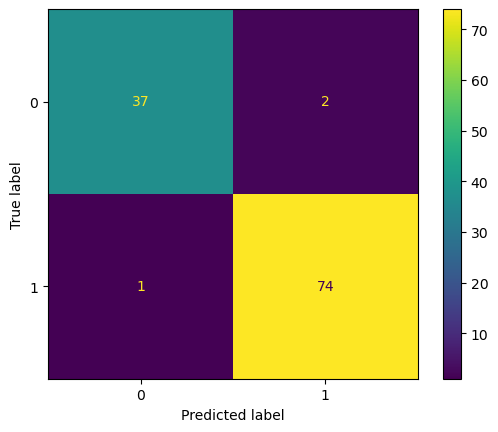

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()